# Dataset provenance and offline ESM feature preparation

This notebook shows how the supplied PET assay records become the confirmed training CSV, and how an amino-acid sequence becomes per-residue ESM features. It runs the original provenance and inclusion scripts against copies of the source records, then checks the regenerated dataset against the packaged one. These records are a collected literature dataset; this notebook does not repeat the original literature collection.

All writes go to a fresh output folder. The original ambiguous-record review is retained as a source artifact. Its six exclusions are not invented by a model. Notebook 01 then removes duplicate or ineligible observations from the 221 confirmed records to obtain 208 modeling rows.

In [1]:
NOTEBOOK_NAME='data_preparation'
from pathlib import Path
import os, sys, json, hashlib, importlib.metadata, datetime, uuid

# Set this only if automatic discovery cannot find your attached Kaggle dataset.
BUNDLE_OVERRIDE = os.environ.get('ENZAIME_NOTEBOOK_ROOT', '')
def find_bundle():
    candidates = [Path(BUNDLE_OVERRIDE)] if BUNDLE_OVERRIDE else []
    candidates += [Path.cwd(), Path.cwd()/'panel_notebooks', Path.cwd().parent]
    if Path('/kaggle/input').exists():
        candidates += [p.parent for p in Path('/kaggle/input').rglob('bundle_manifest.json')]
    valid = list(dict.fromkeys(p.resolve() for p in candidates if (p/'bundle_manifest.json').is_file()))
    if not valid:
        raise FileNotFoundError('Extract EnzAIme_Helix_Notebook_Package.zip, or attach its extracted folder as a Kaggle dataset. Set BUNDLE_OVERRIDE to its panel_notebooks folder.')
    if BUNDLE_OVERRIDE and valid: return valid[0]
    if len(valid)>1: raise ValueError('Multiple bundles found. Set BUNDLE_OVERRIDE to the one to use.')
    return valid[0]

BUNDLE = ROOT = find_bundle()
PET_ROOT = BUNDLE/'pet'
OUTPUT_ROOT = Path(os.environ.get('ENZAIME_NOTEBOOK_OUTPUT',
    '/kaggle/working/enzaime_outputs' if Path('/kaggle/working').exists() else str(BUNDLE/'outputs')))
RUN_DIR = OUTPUT_ROOT/(NOTEBOOK_NAME+'-'+datetime.datetime.now().strftime('%Y%m%d-%H%M%S')+'-'+uuid.uuid4().hex[:6])
RUN_DIR.mkdir(parents=True, exist_ok=False)
os.environ['ENZAIME_ROOT'] = str(PET_ROOT)
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ.setdefault('USE_TF', '0')
os.environ.setdefault('USE_FLAX', '0')
sys.path.insert(0, str(BUNDLE/'lab'))
sys.path.insert(0, str(BUNDLE/'Directed_Evolution-main'))
bundle_manifest = json.loads((BUNDLE/'bundle_manifest.json').read_text(encoding='utf-8'))
def verify_file(relative):
    path = BUNDLE/relative
    expected = bundle_manifest['files'][relative]['sha256']
    observed = hashlib.sha256(path.read_bytes()).hexdigest()
    if observed != expected: raise ValueError(f'Artifact hash mismatch: {relative}')
    return path

print('Data and saved models:', BUNDLE)
print('New outputs:', RUN_DIR)
print('Python:', sys.version.split()[0])

Data and saved models: D:\Enzyme_ML_new\panel_notebooks
New outputs: D:\Enzyme_ML_new\panel_notebooks\outputs\data_preparation-20261026-100222-04512b
Python: 3.12.14


In [2]:
# On a fresh Kaggle session, set True once if the version check below requests it.
# After installation, restart the kernel/session and return this flag to False.
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(BUNDLE/'requirements-kaggle.txt')])
    raise RuntimeError('Dependencies installed. Restart the kernel/session, set INSTALL_DEPENDENCIES=False, then Run All.')

expected_versions={'numpy':'1.26.4','scipy':'1.13.1','scikit-learn':'1.5.2','pandas':'2.2.3'}
mismatches={}
for name, version in expected_versions.items():
    try: actual=importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError: actual='missing'
    if actual != version: mismatches[name]={'installed':actual,'required':version}
if mismatches:
    raise RuntimeError(f'Checkpoint-compatible package versions required: {mismatches}. Run the installation cell with INSTALL_DEPENDENCIES=True, then restart the kernel.')

import copy, csv, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits
_thread_limit = threadpool_limits(limits=2)
plt.rcParams.update({'figure.figsize':(9,4), 'axes.spines.top':False, 'axes.spines.right':False, 'font.size':10})
np.random.seed(42)

def evaluate_predictions(observed, predicted):
    y,p=np.asarray(observed,dtype=float),np.asarray(predicted,dtype=float)
    if y.shape!=p.shape or not np.isfinite(np.column_stack([y,p])).all():
        raise ValueError('Evaluation requires aligned, finite labels and predictions.')
    return {'MAE':float(mean_absolute_error(y,p)), 'RMSE':float(np.sqrt(mean_squared_error(y,p))),
            'R2':float(r2_score(y,p)) if len(y)>1 and np.ptp(y) else None,
            'Spearman':float(spearmanr(y,p).statistic) if np.ptp(y) and np.ptp(p) else None,
            'n':len(y)}

def save_figure(name):
    plt.tight_layout(); plt.savefig(RUN_DIR/(name+'.png'),dpi=160,bbox_inches='tight'); plt.show()

versions={name:importlib.metadata.version(name) for name in expected_versions}
(RUN_DIR/'environment.json').write_text(json.dumps({'python':sys.version,'packages':versions},indent=2))
display(pd.Series(versions,name='Installed version').to_frame())

,Installed version
numpy,1.26.4
scipy,1.13.1
scikit-learn,1.5.2
pandas,2.2.3


## 1. Copy the source records into a writable preparation folder

In [3]:
import shutil
PREP_ROOT=RUN_DIR/'pet_preparation'
for relative in ('master_dataset.csv','data/tpa_pet_ml_dataset.csv','reports/results/tpa_ambiguous_review.md'):
    src=verify_file('pet/'+relative);dest=PREP_ROOT/relative
    dest.parent.mkdir(parents=True,exist_ok=True);shutil.copy2(src,dest)
print('Source records copied to',PREP_ROOT)

Source records copied to D:\Enzyme_ML_new\panel_notebooks\outputs\data_preparation-20261026-100222-04512b\pet_preparation


## 2. Original analyte, unit-conversion and provenance audit
The next cell is the complete original audit script; only its root directory is changed. It reconstructs 227 candidate observations from the collected records, preserves source JSON/DOIs, checks analyte identity and conversion rules, and marks six records as ambiguous.

In [4]:
import hashlib
import json
from collections import Counter
from pathlib import Path

import pandas as pd


PROJECT_ROOT = PREP_ROOT
MASTER_PATH = PROJECT_ROOT / "master_dataset.csv"
ML_PATH = PROJECT_ROOT / "data" / "tpa_pet_ml_dataset.csv"
AUDIT_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "results"
AUDIT_PATH = AUDIT_DIR / "tpa_activity_provenance_audit.csv"
SUMMARY_PATH = REPORT_DIR / "tpa_provenance_audit_summary.json"
AMBIGUOUS_PATH = REPORT_DIR / "tpa_provenance_ambiguous.csv"

MW_TPA = 166.13
CONDITION_COLUMNS = [
    "protein_id",
    "temperature_c",
    "ph",
    "duration_value",
    "duration_unit",
    "substrate",
]


def parse_json(value, default):
    if not isinstance(value, str) or not value.strip():
        return default
    try:
        return json.loads(value)
    except json.JSONDecodeError:
        return default


def as_text(value):
    if value is None:
        return ""
    return str(value).strip()


def as_number(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return None


def values_equal(left, right):
    left_number = as_number(left)
    right_number = as_number(right)
    if left_number is not None and right_number is not None:
        return abs(left_number - right_number) <= max(
            1e-9,
            abs(right_number) * 1e-9,
        )
    return as_text(left) == as_text(right)


def standardize(value, unit, analyte_is_tpa):
    numeric_value = as_number(value)
    normalized_unit = as_text(unit).replace("μ", "µ")
    if numeric_value is None:
        return "", "", "", "invalid_original_value"
    if not analyte_is_tpa:
        return "", "", "", "not_converted_analyte_not_confirmed_tpa"
    if normalized_unit in {"µM", "um", "uM", "µmol/L", "umol/L"}:
        return numeric_value, "µM", "value", "converted"
    if normalized_unit == "mM":
        return numeric_value * 1000, "µM", "value * 1000", "converted"
    if normalized_unit == "µg/mL":
        return (
            numeric_value * 1000 / MW_TPA,
            "µM",
            "value * 1000 / 166.13",
            "converted",
        )
    return "", "", "", "unsupported_unit"


def source_record_matches(row, record):
    conditions = parse_json(record.get("conditions", ""), {})
    if not isinstance(conditions, dict):
        return []
    for row_column, source_column in [
        ("temperature_c", "temperature_c"),
        ("ph", "ph"),
        ("duration_value", "duration_value"),
    ]:
        if source_column not in conditions or not values_equal(
            row[row_column], conditions[source_column]
        ):
            return []
    if as_text(row["duration_unit"]) != as_text(
        conditions.get("duration_unit", "")
    ):
        return []
    if as_text(row["substrate"]) != as_text(record.get("substrate", "")):
        return []

    matches = []
    measurements = parse_json(record.get("measurements", ""), [])
    if not isinstance(measurements, list):
        return matches
    for measurement in measurements:
        if not isinstance(measurement, dict):
            continue
        standardized, _, _, status = standardize(
            measurement.get("value"),
            measurement.get("unit"),
            True,
        )
        target_standardized = standardize(
            row["target_activity"],
            row["unit"],
            True,
        )[0]
        if (
            status == "converted"
            and standardized != ""
            and target_standardized != ""
            and values_equal(standardized, target_standardized)
        ):
            matches.append(measurement)
    return matches


def record_json(record):
    return json.dumps(record, ensure_ascii=False, sort_keys=True)


def source_fields(records, field):
    values = []
    for record in records:
        value = record.get(field, "")
        if isinstance(value, (dict, list)):
            value = json.dumps(value, ensure_ascii=False, sort_keys=True)
        value = as_text(value)
        if value and value not in values:
            values.append(value)
    return "; ".join(values)


def matched_measurements(records, matches):
    output = []
    for record, measurements in zip(records, matches):
        for measurement in measurements:
            output.append((record, measurement))
    return output


def classification(matched):
    if not matched:
        return "NO_TPA_MATCH"
    analytes = [as_text(measurement.get("analyte")) for _, measurement in matched]
    if any(not analyte for analyte in analytes):
        return "UNRESOLVED"
    tpa_matches = [
        analyte for analyte in analytes if analyte.upper() == "TPA"
    ]
    if not tpa_matches:
        return "NO_TPA_MATCH"
    if any(analyte and analyte.upper() != "TPA" for analyte in analytes):
        return "TPA_AMBIGUOUS"
    return "TPA_CONFIRMED"


def condition_group_id(row):
    values = [as_text(row[column]) for column in CONDITION_COLUMNS]
    payload = json.dumps(values, ensure_ascii=False, separators=(",", ":"))
    digest = hashlib.sha256(payload.encode("utf-8")).hexdigest()[:16]
    return f"condition_{digest}"


def build_source_index(master):
    source_index = {}
    for _, row in master.iterrows():
        records = parse_json(row["activity_records_json"], [])
        source_index[as_text(row["protein_id"])] = records
    return source_index


def main():
    master = pd.read_csv(
        MASTER_PATH,
        dtype=str,
        keep_default_na=False,
        low_memory=False,
    )
    ml = pd.read_csv(
        ML_PATH,
        dtype=str,
        keep_default_na=False,
        low_memory=False,
    )
    master_by_id = master.set_index("protein_id", drop=False)
    source_index = build_source_index(master)

    rows = []
    candidate_cache = {}
    for row_index, row in ml.iterrows():
        protein_id = as_text(row["protein_id"])
        candidate_records = []
        candidate_measurements = []
        for record in source_index.get(protein_id, []):
            measurements = source_record_matches(row, record)
            if measurements:
                candidate_records.append(record)
                candidate_measurements.append(measurements)
        matched = matched_measurements(
            candidate_records,
            candidate_measurements,
        )
        candidate_cache[row_index] = (
            candidate_records,
            candidate_measurements,
            matched,
        )

    duplicate_key_counts = ml.groupby(
        list(ml.columns),
        dropna=False,
    ).size()
    duplicate_keys = {
        key for key, count in duplicate_key_counts.items() if count > 1
    }
    condition_key_counts = ml.groupby(
        CONDITION_COLUMNS,
        dropna=False,
    ).size()
    condition_ids = {
        tuple(as_text(value) for value in key): condition_group_id(
            dict(zip(CONDITION_COLUMNS, key))
        )
        for key in condition_key_counts.index
    }

    for row_index, row in ml.iterrows():
        candidate_records, _, matched = candidate_cache[row_index]
        master_row = master_by_id.loc[as_text(row["protein_id"])]
        record_classification = classification(matched)
        analytes = sorted(
            {
                as_text(measurement.get("analyte"))
                for _, measurement in matched
                if as_text(measurement.get("analyte"))
            }
        )
        metric_types = sorted(
            {
                as_text(measurement.get("metric_type"))
                for _, measurement in matched
                if as_text(measurement.get("metric_type"))
            }
        )
        tpa_confirmed = record_classification == "TPA_CONFIRMED"
        standardized_value, standardized_unit, formula, conversion_status = (
            standardize(
                row["target_activity"],
                row["unit"],
                tpa_confirmed,
            )
        )
        if record_classification == "TPA_AMBIGUOUS":
            conversion_status = "not_converted_ambiguous_analyte"
            standardized_value = ""
            standardized_unit = ""
            formula = ""
        key = tuple(as_text(row[column]) for column in CONDITION_COLUMNS)
        full_key = tuple(row[column] for column in ml.columns)
        output = {
            "protein_id": row["protein_id"],
            "protein_name": row["protein_name"],
            "sequence": row["sequence"],
            "uniprot_accession": master_row.get("uniprot_accessions", ""),
            "uniprot_entry": master_row.get("uniprot_entry", ""),
            "ec_number": master_row.get("ec_number", ""),
            "substrate": row["substrate"],
            "target_name": "; ".join(analytes),
            "target_value": row["target_activity"],
            "target_unit": row["unit"],
            "target_value_standardized": standardized_value,
            "standardized_unit": standardized_unit,
            "analyte": "; ".join(analytes),
            "metric_type": "; ".join(metric_types),
            "temperature_c": row["temperature_c"],
            "ph": row["ph"],
            "duration_value": row["duration_value"],
            "duration_unit": row["duration_unit"],
            "duration_hours": (
                as_number(row["duration_value"])
                * (24 if row["duration_unit"] == "d" else 1)
            ),
            "assay_method": source_fields(candidate_records, "detection_methods"),
            "material_description": source_fields(candidate_records, "material"),
            "source": source_fields(candidate_records, "evidence"),
            "source_file": source_fields(candidate_records, "source_file"),
            "source_record_id": "",
            "assay_index": source_fields(candidate_records, "assay_index"),
            "measurement_index": "",
            "replicate_n": "; ".join(
                sorted(
                    {
                        as_text(measurement.get("replicate_n"))
                        for _, measurement in matched
                        if as_text(measurement.get("replicate_n"))
                    }
                )
            ),
            "literature_doi": source_fields(
                candidate_records,
                "literature_doi",
            ),
            "conversion_formula": formula,
            "molecular_weight_used": MW_TPA if row["unit"] == "µg/mL" and tpa_confirmed else "",
            "conversion_status": conversion_status,
            "classification": record_classification,
            "possible_duplicate": full_key in duplicate_keys,
            "condition_group_id": condition_ids[key],
            "repeated_condition": condition_key_counts.loc[key] > 1,
            "zero_duration_flag": as_number(row["duration_value"]) == 0,
            "original_record_json": json.dumps(
                candidate_records,
                ensure_ascii=False,
                sort_keys=True,
            ),
        }
        rows.append(output)

    audit = pd.DataFrame(rows)
    AUDIT_DIR.mkdir(parents=True, exist_ok=True)
    REPORT_DIR.mkdir(parents=True, exist_ok=True)
    audit.to_csv(AUDIT_PATH, index=False, encoding="utf-8-sig")

    ambiguous = audit[audit.classification.isin(["TPA_AMBIGUOUS", "UNRESOLVED"])]
    ambiguous.to_csv(AMBIGUOUS_PATH, index=False, encoding="utf-8-sig")

    duplicate_groups = ml[ml.duplicated(list(ml.columns), keep=False)].drop_duplicates(list(ml.columns))
    repeated_rows = audit[audit.repeated_condition]
    matched_count = int(audit.original_record_json.ne("[]").sum())
    analyte_counts = Counter()
    for analyte_value in audit["analyte"]:
        analyte_counts.update(
            analyte
            for analyte in analyte_value.split("; ")
            if analyte
        )
    summary = {
        "total_ml_records": len(ml),
        "matched_records": matched_count,
        "unmatched_records": len(ml) - matched_count,
        "classification_counts": {
            key: int(audit.classification.eq(key).sum())
            for key in [
                "TPA_CONFIRMED",
                "TPA_AMBIGUOUS",
                "NO_TPA_MATCH",
                "UNRESOLVED",
            ]
        },
        "unit_counts": ml["unit"].value_counts().to_dict(),
        "analyte_counts": dict(analyte_counts),
        "protein_counts": ml["protein_name"].value_counts().to_dict(),
        "source_counts": audit["source_file"].replace("", "(blank)").value_counts().to_dict(),
        "exact_duplicate_groups": len(duplicate_groups),
        "exact_duplicate_rows": int(audit.possible_duplicate.sum()),
        "repeated_condition_groups": int(condition_key_counts.gt(1).sum()),
        "repeated_condition_rows": len(repeated_rows),
        "zero_duration_rows": int(audit.zero_duration_flag.sum()),
        "conversion_status_counts": audit["conversion_status"].value_counts().to_dict(),
        "output_row_count": len(audit),
        "source_record_id_available": False,
        "measurement_index_available": False,
    }
    SUMMARY_PATH.write_text(
        json.dumps(summary, indent=2, ensure_ascii=False) + "\n",
        encoding="utf-8",
    )

    print("1. Total ML rows:", len(ml))
    print("2. Matched rows:", matched_count)
    print("3. Unmatched rows:", len(ml) - matched_count)
    for key, value in summary["classification_counts"].items():
        print(f"{key} count:", value)
    print("8. Exact duplicate groups:", len(duplicate_groups))
    print("9. Repeated-condition groups:", summary["repeated_condition_groups"])
    print("10. Zero-duration rows:", summary["zero_duration_rows"])
    print("11. Unit counts:", summary["unit_counts"])
    print("12. Conversion status counts:", summary["conversion_status_counts"])
    print("13. First 10 ambiguous/unresolved records:")
    print(
        ambiguous[
            [
                "protein_id",
                "protein_name",
                "target_value",
                "target_unit",
                "temperature_c",
                "ph",
                "duration_value",
                "duration_unit",
                "analyte",
                "classification",
            ]
        ].head(10).to_string(index=False)
    )
    print("Output row count:", len(audit))
    print("Raw/master/model files modified: no")
    print("Model training performed: no")
    print("READY FOR REVIEW")


if __name__ == "__main__":
    main()

1. Total ML rows: 227
2. Matched rows: 227
3. Unmatched rows: 0
TPA_CONFIRMED count: 221
TPA_AMBIGUOUS count: 6
NO_TPA_MATCH count: 0
UNRESOLVED count: 0
8. Exact duplicate groups: 6
9. Repeated-condition groups: 51
10. Zero-duration rows: 10
11. Unit counts: {'µM': 143, 'µmol/L': 45, 'mM': 27, 'µg/mL': 12}
12. Conversion status counts: {'converted': 221, 'not_converted_ambiguous_analyte': 6}
13. First 10 ambiguous/unresolved records:
protein_id protein_name target_value target_unit temperature_c  ph duration_value duration_unit                                          analyte classification
        41        PET46         1.91          µM          30.0 8.0             72             h TPA; TPA + MHET + BHET (total aromatic products)  TPA_AMBIGUOUS
        42         CalB          3.4          µM          37.0 7.0             28             d                                        BHET; TPA  TPA_AMBIGUOUS
        42         CalB          3.4          µM          37.0 7.0             28

## 3. Original confirmed-dataset selection
This cell applies the recorded review and writes the 221 confirmed TPA measurements. Ambiguous records are exported separately with their recorded reasons.

In [5]:
import json
import re
from pathlib import Path

import pandas as pd


PROJECT_ROOT = PREP_ROOT
AUDIT_PATH = PROJECT_ROOT / "data" / "processed" / "tpa_activity_provenance_audit.csv"
REVIEW_PATH = PROJECT_ROOT / "reports" / "results" / "tpa_ambiguous_review.md"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "results"
CONFIRMED_PATH = OUTPUT_DIR / "tpa_pet_ml_confirmed.csv"
AMBIGUOUS_PATH = OUTPUT_DIR / "tpa_pet_ambiguous_excluded.csv"
SUMMARY_PATH = REPORT_DIR / "tpa_confirmed_dataset_summary.json"
PROTEIN_COUNTS_PATH = REPORT_DIR / "tpa_confirmed_protein_counts.csv"


def non_empty(series):
    return series.fillna("").astype(str).str.strip().ne("")


def numeric_summary(series):
    values = pd.to_numeric(series, errors="coerce")
    return {
        "min": float(values.min()),
        "max": float(values.max()),
        "mean": float(values.mean()),
        "median": float(values.median()),
        "standard_deviation": float(values.std()),
    }


def main():
    audit = pd.read_csv(
        AUDIT_PATH,
        dtype=str,
        keep_default_na=False,
        low_memory=False,
    )
    review = REVIEW_PATH.read_text(encoding="utf-8")
    reasons = re.findall(r"\*\*Reason:\*\* (.+)", review)

    ambiguous = audit[audit["classification"] == "TPA_AMBIGUOUS"].copy()
    confirmed = audit[audit["classification"] == "TPA_CONFIRMED"].copy()

    assert len(audit) == 227
    assert len(confirmed) == 221
    assert len(ambiguous) == 6
    assert len(reasons) == len(ambiguous)

    ambiguous.insert(
        len(ambiguous.columns),
        "exclusion_reason",
        reasons,
    )

    required_columns = [
        "protein_id",
        "protein_name",
        "sequence",
        "uniprot_accession",
        "uniprot_entry",
        "ec_number",
        "substrate",
        "target_name",
        "target_value",
        "target_unit",
        "target_value_standardized",
        "standardized_unit",
        "analyte",
        "metric_type",
        "temperature_c",
        "ph",
        "duration_value",
        "duration_unit",
        "duration_hours",
        "assay_method",
        "material_description",
        "source",
        "source_file",
        "source_record_id",
        "assay_index",
        "measurement_index",
        "replicate_n",
        "literature_doi",
        "conversion_formula",
        "molecular_weight_used",
        "conversion_status",
        "classification",
        "possible_duplicate",
        "condition_group_id",
        "repeated_condition",
        "zero_duration_flag",
        "original_record_json",
    ]
    missing_columns = [column for column in required_columns if column not in audit]
    assert not missing_columns, missing_columns

    required_confirmed_fields = [
        "sequence",
        "target_value",
        "temperature_c",
        "ph",
        "duration_value",
        "duration_unit",
    ]
    missing_confirmed_values = {
        column: int((~non_empty(confirmed[column])).sum())
        for column in required_confirmed_fields
    }
    missing_confirmed_values = {
        key: value for key, value in missing_confirmed_values.items() if value
    }
    assert not missing_confirmed_values, missing_confirmed_values

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    REPORT_DIR.mkdir(parents=True, exist_ok=True)
    confirmed.to_csv(CONFIRMED_PATH, index=False, encoding="utf-8-sig")
    ambiguous.to_csv(AMBIGUOUS_PATH, index=False, encoding="utf-8-sig")

    protein_counts = (
        confirmed.groupby(["protein_name", "protein_id"], as_index=False)
        .size()
        .rename(columns={"size": "record_count"})
        .sort_values(
            ["record_count", "protein_name", "protein_id"],
            ascending=[False, True, True],
        )
    )
    protein_counts.to_csv(PROTEIN_COUNTS_PATH, index=False, encoding="utf-8-sig")

    standardized_target = pd.to_numeric(
        confirmed["target_value_standardized"],
        errors="coerce",
    )
    confirmed_condition_counts = confirmed.groupby(
        "condition_group_id",
        dropna=False,
    ).size()
    confirmed_duplicate_counts = confirmed.groupby(
        list(audit.columns),
        dropna=False,
    ).size()
    confirmed_duplicate_groups = int((confirmed_duplicate_counts > 1).sum())
    confirmed_duplicate_rows = int(
        confirmed["possible_duplicate"].astype(str).str.lower().eq("true").sum()
    )
    available_uniprot = non_empty(confirmed.drop_duplicates("protein_id")["uniprot_accession"])
    zero_duration = confirmed["zero_duration_flag"].astype(str).str.lower().eq("true")

    summary = {
        "total_original_records": len(audit),
        "confirmed_records": len(confirmed),
        "excluded_ambiguous_records": len(ambiguous),
        "protein_count": int(confirmed["protein_id"].nunique()),
        "unique_proteins": int(confirmed["protein_id"].nunique()),
        "target_statistics": {
            "field": "target_value_standardized",
            **numeric_summary(standardized_target),
        },
        "condition_statistics": {
            "ph": {
                "min": float(pd.to_numeric(confirmed["ph"]).min()),
                "max": float(pd.to_numeric(confirmed["ph"]).max()),
            },
            "temperature_c": {
                "min": float(pd.to_numeric(confirmed["temperature_c"]).min()),
                "max": float(pd.to_numeric(confirmed["temperature_c"]).max()),
            },
            "duration_hours": {
                "min": float(pd.to_numeric(confirmed["duration_hours"]).min()),
                "max": float(pd.to_numeric(confirmed["duration_hours"]).max()),
            },
        },
        "unit_counts": confirmed["target_unit"].value_counts().to_dict(),
        "protein_record_counts": dict(
            zip(
                protein_counts["protein_id"],
                protein_counts["record_count"],
            )
        ),
        "zero_duration_count": int(zero_duration.sum()),
        "duplicate_group_count": confirmed_duplicate_groups,
        "duplicate_rows_involved": confirmed_duplicate_rows,
        "repeated_condition_group_count": int(
            (confirmed_condition_counts > 1).sum()
        ),
        "uniprot_available_count": int(available_uniprot.sum()),
        "uniprot_missing_count": int((~available_uniprot).sum()),
        "missing_confirmed_values": missing_confirmed_values,
    }
    SUMMARY_PATH.write_text(
        json.dumps(summary, indent=2, ensure_ascii=False) + "\n",
        encoding="utf-8",
    )

    assert len(confirmed) == 221
    assert len(ambiguous) == 6
    assert set(confirmed["classification"]) == {"TPA_CONFIRMED"}
    assert not set(ambiguous.index).intersection(confirmed.index)
    assert not missing_confirmed_values

    print("========================================")
    print("ENZAIme CONFIRMED DATASET")
    print("========================================")
    print("Original records:", len(audit))
    print("Confirmed TPA records:", len(confirmed))
    print("Excluded ambiguous records:", len(ambiguous))
    print("Unique proteins:", summary["unique_proteins"])
    print()
    print("Target:")
    print("Min:", summary["target_statistics"]["min"])
    print("Median:", summary["target_statistics"]["median"])
    print("Mean:", summary["target_statistics"]["mean"])
    print("Max:", summary["target_statistics"]["max"])
    print()
    print("pH:")
    print("Min:", summary["condition_statistics"]["ph"]["min"])
    print("Max:", summary["condition_statistics"]["ph"]["max"])
    print()
    print("Temperature:")
    print("Min:", summary["condition_statistics"]["temperature_c"]["min"])
    print("Max:", summary["condition_statistics"]["temperature_c"]["max"])
    print()
    print("Duration:")
    print("Min:", summary["condition_statistics"]["duration_hours"]["min"])
    print("Max:", summary["condition_statistics"]["duration_hours"]["max"])
    print()
    print("Exact duplicate groups:", summary["duplicate_group_count"])
    print("Repeated condition groups:", summary["repeated_condition_group_count"])
    print("Zero-duration rows:", summary["zero_duration_count"])
    print()
    print("UniProt available:", summary["uniprot_available_count"])
    print("UniProt missing:", summary["uniprot_missing_count"])
    print()
    print("Top proteins by record count:")
    print(protein_counts.to_string(index=False))
    print()
    print("Low-count proteins:")
    print(protein_counts[protein_counts["record_count"] <= 5].to_string(index=False))
    print()
    print("========================================")
    print("Confirmed dataset row count:", len(confirmed))
    print("Ambiguous dataset row count:", len(ambiguous))
    print("Missing confirmed required fields:", missing_confirmed_values)
    print("Original ML/master/model files modified: no")
    print("Model training performed: no")
    print("ESM-2 embeddings regenerated: no")
    print("CONFIRMED DATASET READY")


if __name__ == "__main__":
    main()

ENZAIme CONFIRMED DATASET
Original records: 227
Confirmed TPA records: 221
Excluded ambiguous records: 6
Unique proteins: 25

Target:
Min: 0.3
Median: 194.8
Mean: 1472.0770740185205
Max: 47000.0

pH:
Min: 7.0
Max: 9.0

Temperature:
Min: 25.0
Max: 80.0

Duration:
Min: 0.0
Max: 672.0

Exact duplicate groups: 4
Repeated condition groups: 48
Zero-duration rows: 8

UniProt available: 15
UniProt missing: 10

Top proteins by record count:
protein_name protein_id  record_count
         HiC         44            75
        CalB         42            20
         606        149            13
       DIEGO        483            12
    IsPETase          1            12
         MG8         13            12
         Sis        481            12
        Sub1        177            12
       BurPL        195             8
       PHL-7         37             8
    RgPETase         15             8
     SM14est        185             7
   BhrPETase         17             5
        CtPl        148         

,protein_id,protein_name,temperature_c,ph,duration_hours,target_value_standardized,standardized_unit,literature_doi
0,1,IsPETase,30.0,9.0,24.0,1.3,µM,10.1021/acscatal.9b00568
1,1,IsPETase,30.0,9.0,72.0,2.4,µM,10.1021/acscatal.9b00568
2,1,IsPETase,40.0,9.0,24.0,2.1,µM,10.1021/acscatal.9b00568
3,1,IsPETase,40.0,9.0,72.0,3.3,µM,10.1021/acscatal.9b00568
4,1,IsPETase,30.0,7.0,18.0,58.0,µM,10.1126/science.aad6359


Reproduced all 221 confirmed rows and all 37 columns exactly as parsed.


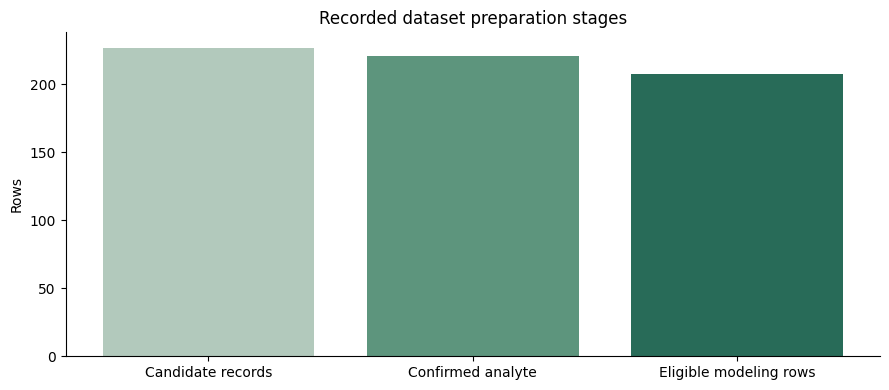

In [6]:
regenerated=pd.read_csv(PREP_ROOT/'data/processed/tpa_pet_ml_confirmed.csv',dtype=str,keep_default_na=False)
packaged=pd.read_csv(verify_file('pet/data/processed/tpa_pet_ml_confirmed.csv'),dtype=str,keep_default_na=False)
pd.testing.assert_frame_equal(regenerated,packaged)
display(regenerated[['protein_id','protein_name','temperature_c','ph','duration_hours','target_value_standardized','standardized_unit','literature_doi']].head())
print('Reproduced all',len(regenerated),'confirmed rows and all',len(regenerated.columns),'columns exactly as parsed.')
fig,ax=plt.subplots()
ax.bar(['Candidate records','Confirmed analyte','Eligible modeling rows'],[227,221,208],color=['#b2c9bc','#5d957d','#286b58'])
ax.set(ylabel='Rows',title='Recorded dataset preparation stages')
save_figure('01_dataset_preparation_counts')

## 4. Complete offline sequence-feature function
The PET checkpoint expects the frozen **ESM-2 35M** encoder and 480 channels. The function below explicitly excludes the special start/end tokens, verifies standard amino acids and records the sequence hash. It regenerates one catalog protein for an on-the-spot check. Set `REBUILD_ALL_PROTEINS=True` before running to encode all 25 proteins. New files are saved in the output folder and do not replace the original cache.

Images in the old PET checkpoint are disabled (`image_trained=false`). We therefore use a zero image vector and mark it absent, matching the original sequence-only feature preparation. Structural visualizations are shown separately in notebook 01; they do not manufacture measured activity labels.

In [7]:
import torch
from transformers import AutoModel,AutoTokenizer
torch.set_num_threads(2)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
esm_path=BUNDLE/'models/esm2_35m'
verify_file('models/esm2_35m/model.safetensors')
feature_tokenizer=AutoTokenizer.from_pretrained(str(esm_path),local_files_only=True)
feature_encoder=AutoModel.from_pretrained(str(esm_path),local_files_only=True).to(DEVICE).eval()
AA_STANDARD=set('ACDEFGHIKLMNPQRSTVWY')

@torch.inference_mode()
def encode_pet_sequence(sequence):
    sequence=str(sequence).strip().upper()
    if not sequence or len(sequence)>1022 or set(sequence)-AA_STANDARD:
        raise ValueError('Use 1–1022 standard amino acids, without a FASTA header.')
    tokens=feature_tokenizer(sequence,return_tensors='pt').to(DEVICE)
    hidden=feature_encoder(**tokens).last_hidden_state[0,1:len(sequence)+1]
    features=hidden.cpu().numpy().astype(np.float32)
    assert features.shape==(len(sequence),480)
    return features,hashlib.sha256(sequence.encode()).hexdigest()

REBUILD_ALL_PROTEINS=False
catalog_rows=packaged.drop_duplicates('protein_id').set_index('protein_id')
selected=list(catalog_rows.index) if REBUILD_ALL_PROTEINS else ['1']
feature_output=RUN_DIR/'neural_features';feature_output.mkdir()
feature_index={}
old_index=json.loads(verify_file('pet/data/neural_features/index.json').read_text())
for pid in selected:
    sequence=catalog_rows.loc[pid,'sequence']
    representation,digest=encode_pet_sequence(sequence)
    old=old_index['proteins'][pid]
    assert digest==old['sequence_sha256']
    with np.load(verify_file('pet/data/neural_features/'+old['file']),allow_pickle=False) as cached:
        difference=float(np.max(np.abs(representation-cached['sequence'])))
        np.testing.assert_allclose(representation,cached['sequence'],rtol=2e-3,atol=2e-3)
    name=pid+'.npz'
    np.savez_compressed(feature_output/name,sequence=representation,image=np.zeros(512,dtype=np.float32))
    feature_index[pid]={'file':name,'sequence_sha256':digest,'sequence_length':len(sequence),'image_present':False}
    print(f'Protein {pid}: {representation.shape}; maximum difference from original cache {difference:.6g}')
(feature_output/'index.json').write_text(json.dumps({'encoder':old_index['encoder'],'image_encoder':old_index['image_encoder'],
    'proteins':feature_index,'scope':'all catalog proteins' if REBUILD_ALL_PROTEINS else 'single-protein demonstration'},indent=2))
print('Feature files:',feature_output)

D:\Enzyme_ML_new\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


D:\Enzyme_ML_new\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Some weights of EsmModel were not initialized from the model checkpoint at D:\Enzyme_ML_new\panel_notebooks\models\esm2_35m and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Protein 1: (290, 480); maximum difference from original cache 8.76188e-06
Feature files: D:\Enzyme_ML_new\panel_notebooks\outputs\data_preparation-20261026-100222-04512b\neural_features


## 5. Outputs and what happens next
Use notebook 01 to load the verified complete feature cache, clean the 221-row CSV, fit training-only transforms, train models and evaluate saved checkpoints. Use `encode_pet_sequence` to prepare new sequence features; an unseen sequence has no measured label merely because features can be computed. New mutant activity and a new 3D fold remain separate prediction/validation problems.

In [8]:
preparation_summary={'confirmed_rows':len(regenerated),'all_columns_match':True,'regenerated_proteins':selected,
    'encoder_source':json.loads((esm_path/'SOURCE.json').read_text()),'new_output_directory':str(RUN_DIR)}
(RUN_DIR/'summary.json').write_text(json.dumps(preparation_summary,indent=2))
display(pd.DataFrame({'Output':[str(p.relative_to(RUN_DIR)) for p in sorted(RUN_DIR.rglob('*')) if p.is_file()]}))

,Output
0,01_dataset_preparation_counts.png
1,environment.json
2,neural_features\1.npz
3,neural_features\index.json
4,pet_preparation\data\processed\tpa_activity_pr...
5,pet_preparation\data\processed\tpa_pet_ambiguo...
6,pet_preparation\data\processed\tpa_pet_ml_conf...
7,pet_preparation\data\tpa_pet_ml_dataset.csv
8,pet_preparation\master_dataset.csv
9,pet_preparation\reports\results\tpa_ambiguous_...
